**NAME_VAISHNAV BALPANDE\
SECTION-C2\
ROLL NO-B1-01\
SUBJECT-ML LAB**

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score,classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [120]:
df=pd.read_csv('seeds_new.csv')

In [121]:
display(df.head())

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [122]:
print(df.shape)

(210, 10)


In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [124]:
print(df.isnull().sum())

Area                         0
Perimeter                    0
Compactness                  0
Length of kernel             0
Width of kernel              0
Asymmetry coefficient        0
Length of kernel groove      0
Class (1, 2, 3)              0
Unnamed: 8                 208
Unnamed: 9                 209
dtype: int64


In [125]:
display(df.head())

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [126]:
print(df.shape)

(210, 10)


In [127]:
display(df.describe())

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [128]:
df = df.drop(columns=['Unnamed: 8', 'Unnamed: 9'], errors='ignore')

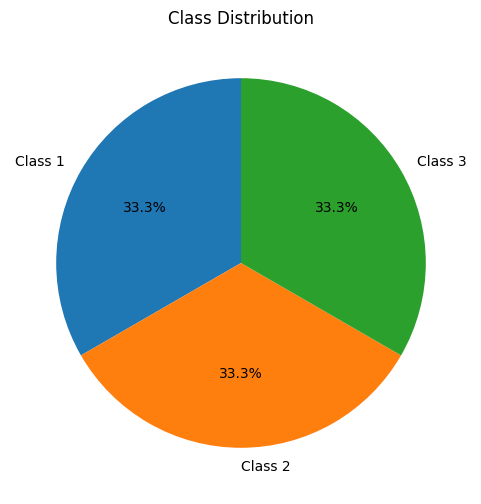

In [129]:
class_counts=df["Class (1, 2, 3)"].value_counts().sort_index()
plt.figure(figsize=(6,6))
plt.pie(class_counts,labels=["Class 1","Class 2","Class 3"],autopct="%1.1f%%",startangle=90)
plt.title("Class Distribution")
plt.show()

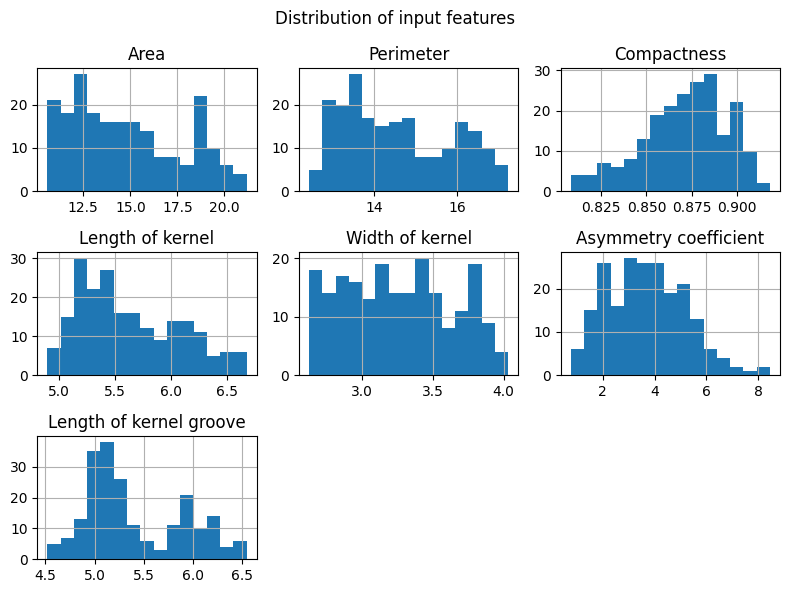

In [130]:
df.drop("Class (1, 2, 3)",axis=1, errors='ignore').hist(figsize=(8,6),bins=15)
plt.suptitle("Distribution of input features")
plt.tight_layout()
plt.show()

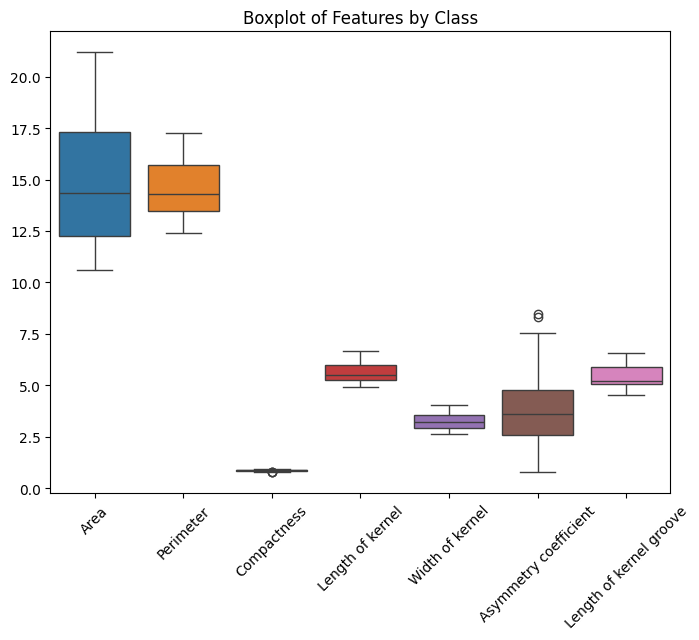

In [131]:
plt.figure(figsize=(8,6))
sns.boxplot(data=df.drop('Class (1, 2, 3)', axis=1))
plt.title('Boxplot of Features by Class')
plt.xticks(rotation=45)
plt.show()

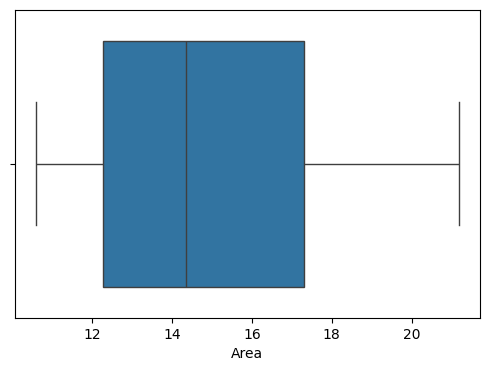

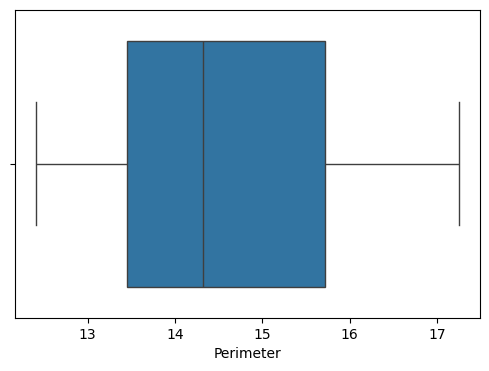

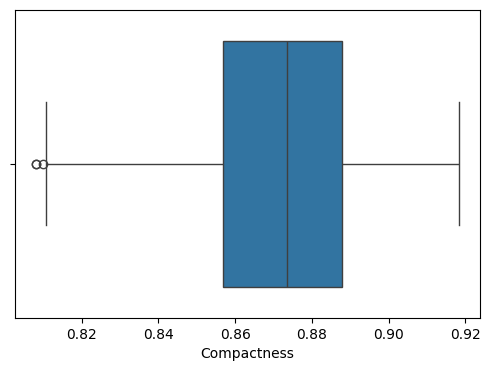

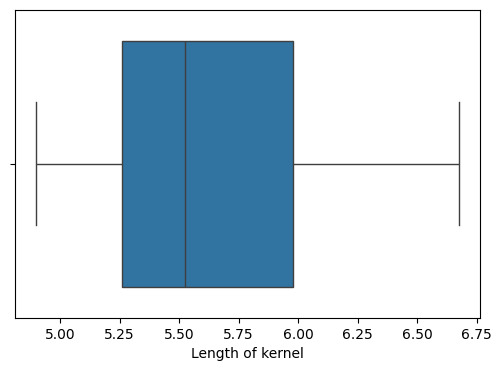

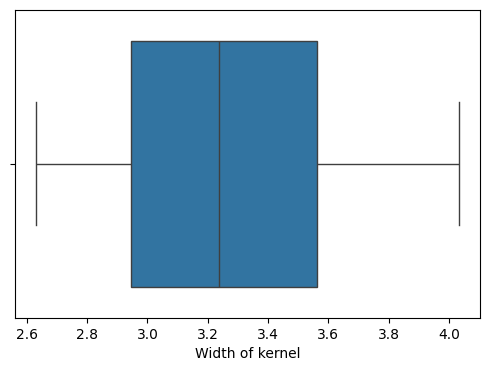

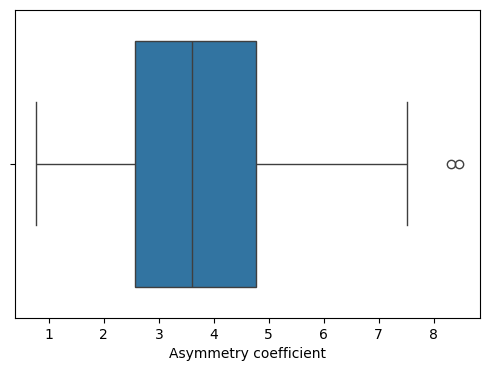

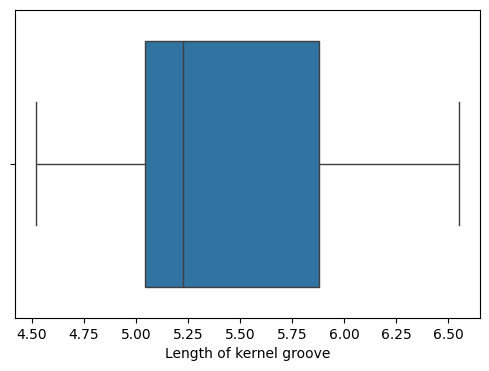

In [132]:
features=df.drop('Class (1, 2, 3)',axis=1).columns
for feature in features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[feature])
    plt.xlabel(feature)
    plt.show()

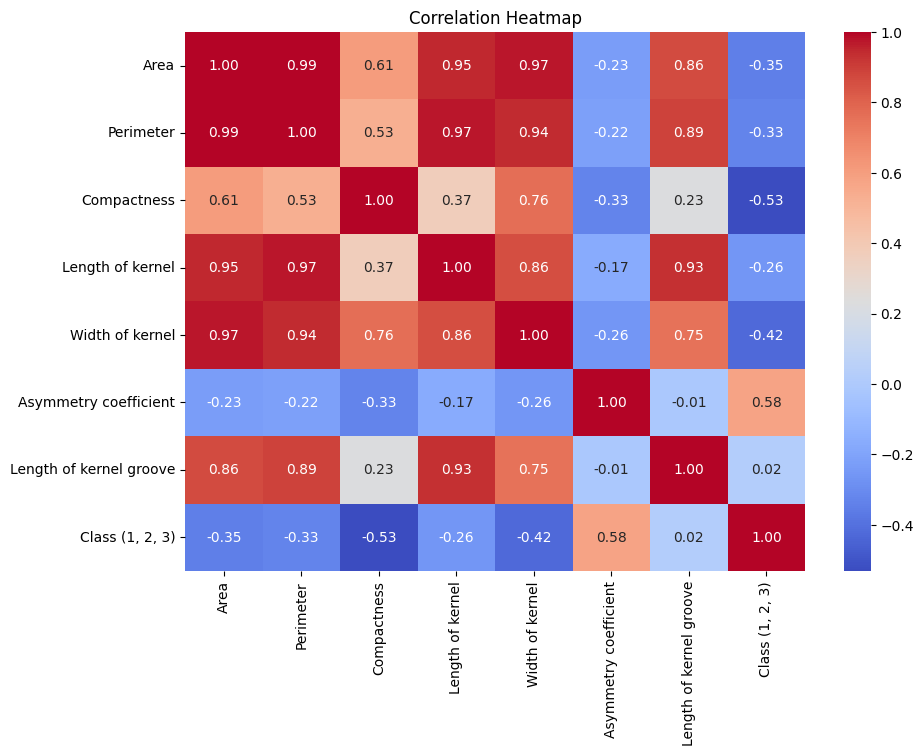

In [133]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm',fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

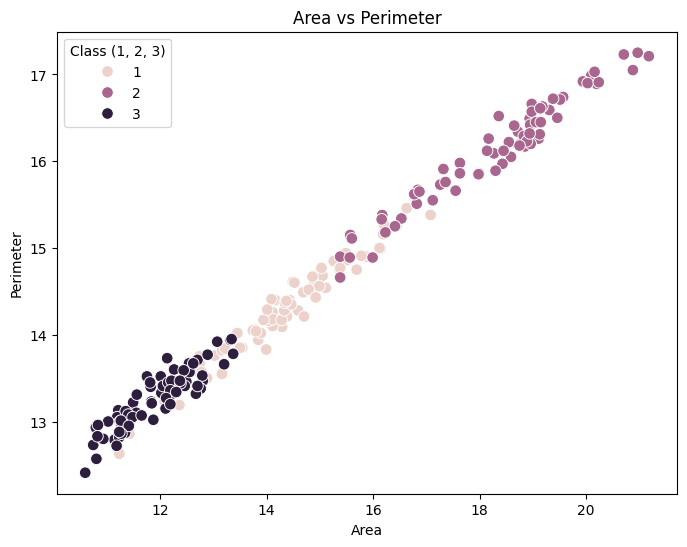

In [134]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x='Area',y='Perimeter',hue='Class (1, 2, 3)',s=70)
plt.title("Area vs Perimeter")
plt.show()

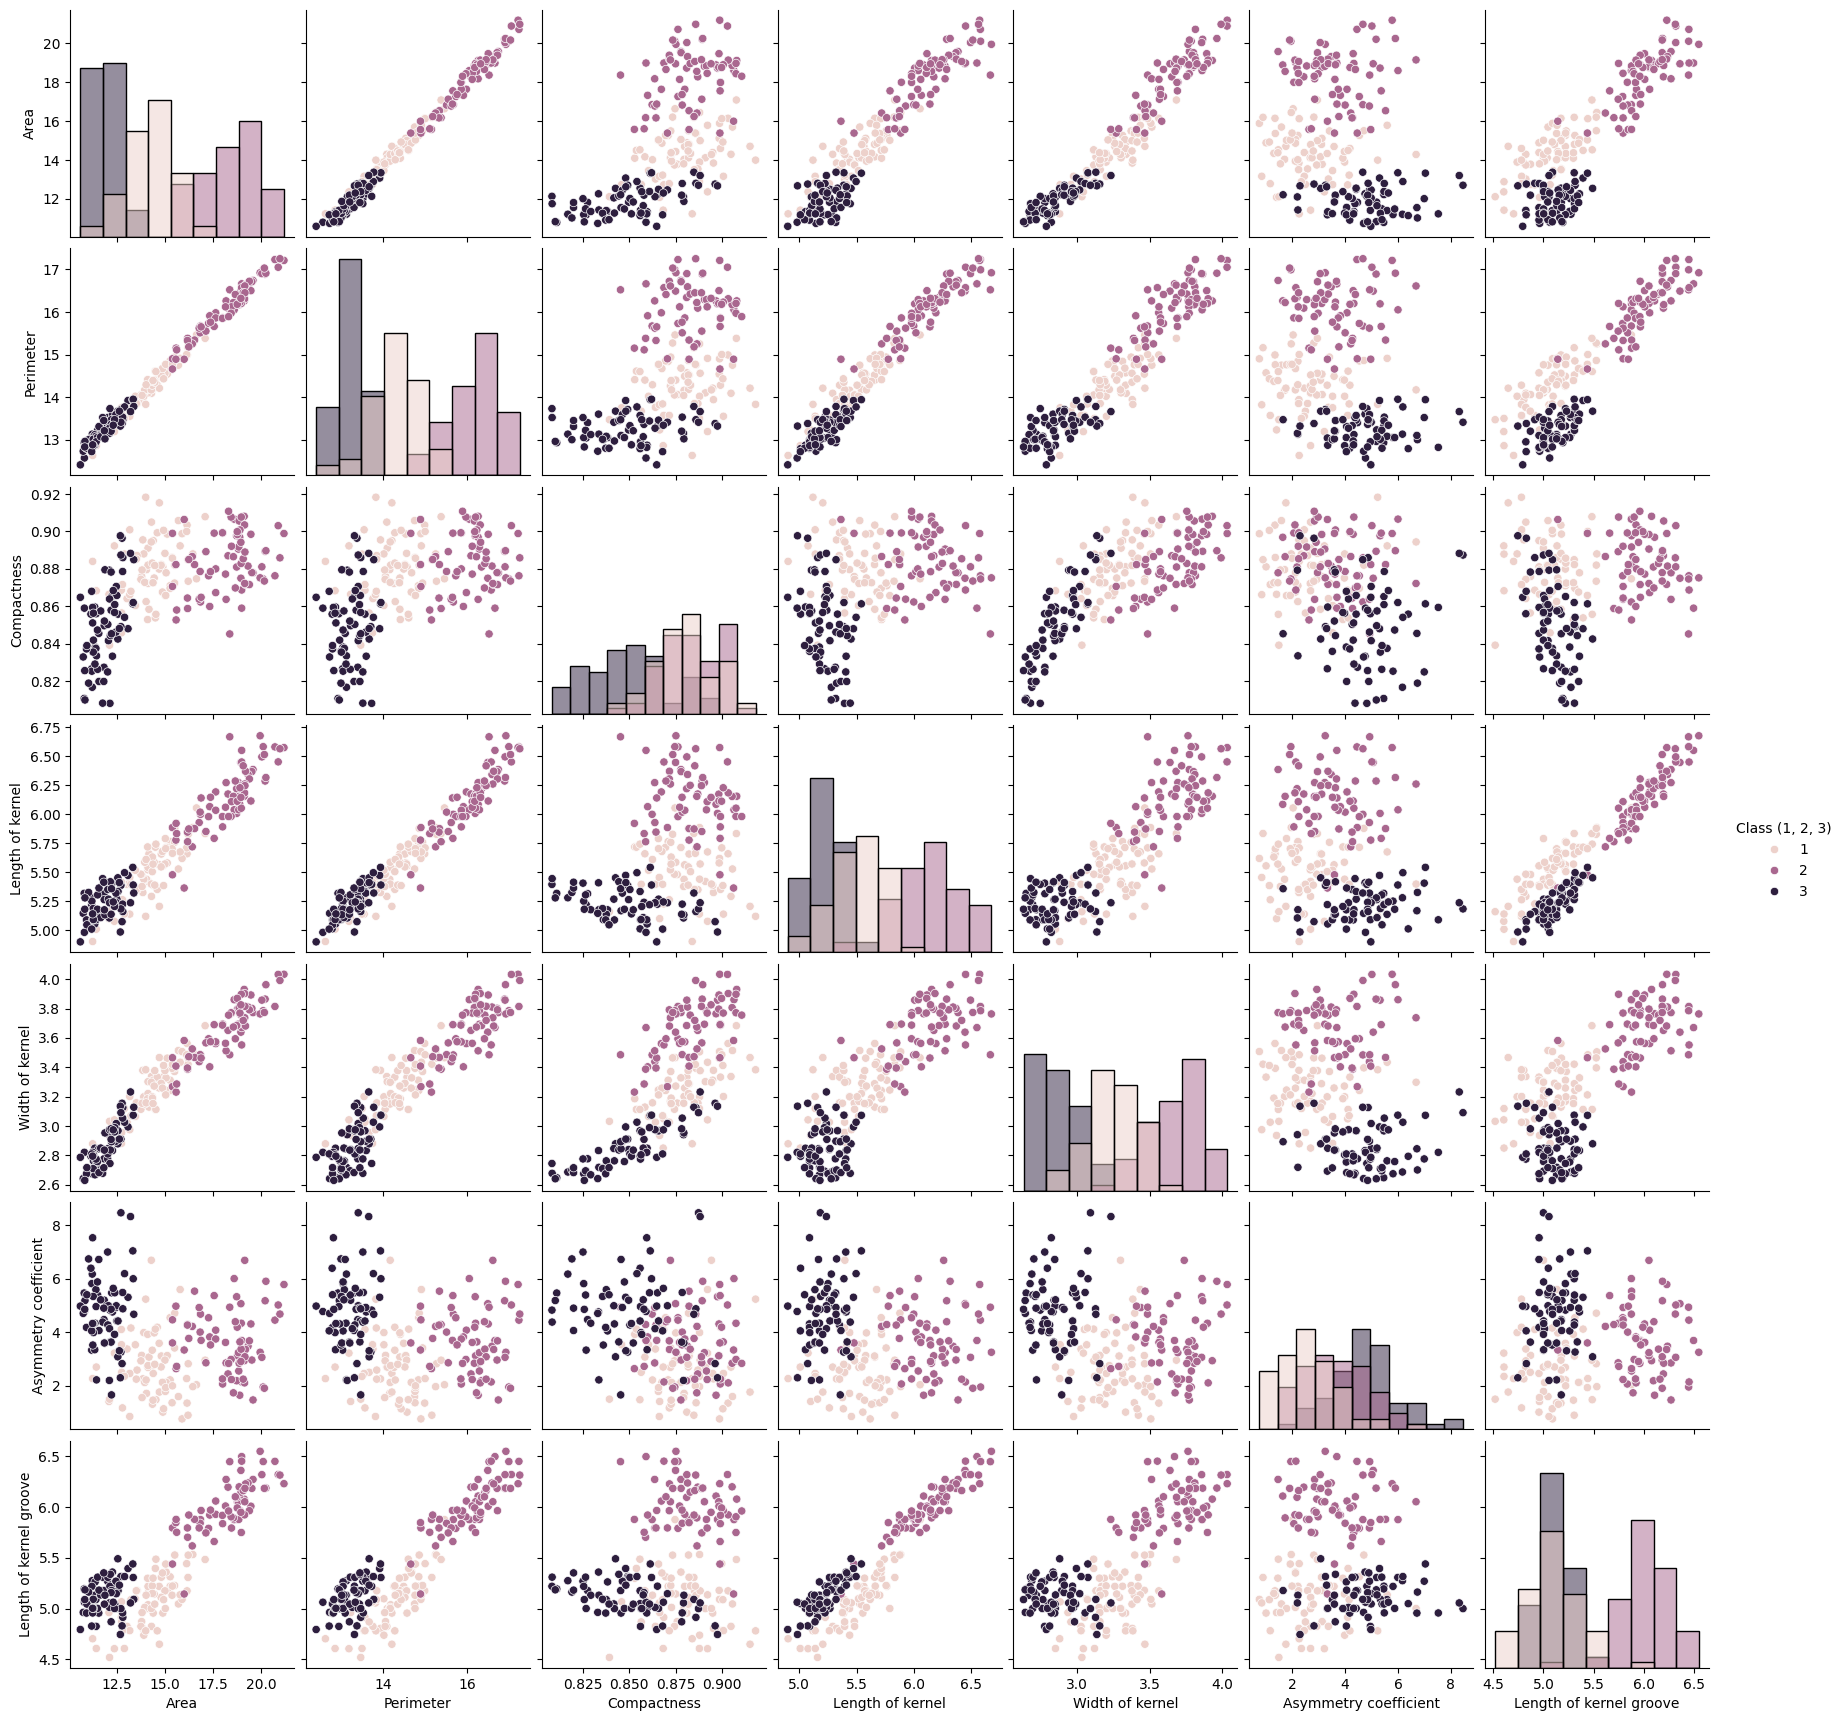

In [135]:
sns.pairplot(df,hue='Class (1, 2, 3)',diag_kind='hist')
plt.show()

In [136]:
X=df.drop('Class (1, 2, 3)',axis=1)
y_original=df['Class (1, 2, 3)']
print("Input Shape",X.shape)
print("Target Shape",y_original.shape)

Input Shape (210, 7)
Target Shape (210,)


In [137]:
y=y_original-1
print("Original Class:")
print(sorted(y_original.unique()))
print("\n ANN encoded_classes:")
print(sorted(y.unique()))

Original Class:
[np.int64(1), np.int64(2), np.int64(3)]

 ANN encoded_classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [138]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train Shape:",X_train.shape[0])
print("X_test Shape:",X_test.shape[0])

X_train Shape: 168
X_test Shape: 42


In [139]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [140]:
scaler.fit_transform(X_test)

array([[-0.52991291, -0.49623599, -0.27871655, -0.28725548, -0.68950684,
        -1.89773913, -0.63786437],
       [-1.17566801, -1.13903806, -1.3157494 , -1.08016108, -1.23712694,
         0.29497821, -0.74893692],
       [ 1.63968755,  1.68929104,  0.22486319,  1.68850928,  1.44414504,
        -0.56016822,  1.60143767],
       [-0.66658066, -0.82898059,  1.01010617, -1.11265721, -0.22454638,
        -0.64523847, -1.08612146],
       [-1.12441761, -1.22222421, -0.18909643, -1.25347378, -1.01239605,
        -0.7264996 , -1.52842824],
       [-1.20300156, -1.07853904, -2.02417513, -0.72920286, -1.46444094,
         1.24979649, -0.3145639 ],
       [-0.31124452, -0.32986369,  0.28460994, -0.45623536, -0.22454638,
        -1.45023154, -0.82629102],
       [-0.8613322 , -0.84410535, -0.63292941, -0.75086695, -0.85999234,
         0.64287742, -0.43555364],
       [ 0.5907626 ,  0.58518396,  0.65162568,  0.64430027,  0.6795434 ,
        -1.19057684,  0.30823578],
       [-0.65633058, -0.7155

In [141]:
print("First S scaled training samples:")
print(X_train_scaled[:5])

First S scaled training samples:
[[-1.05385596 -1.04083248 -0.88880831 -0.86174582 -1.13018592  1.03548208
  -0.22342116]
 [ 1.52927104  1.5495697   0.46355711  1.60878046  1.46287997 -0.1265987
   1.69031688]
 [-0.86392015 -0.87893234 -0.40975723 -0.96258363 -0.73186961  1.222849
  -0.76198116]
 [-0.17669786 -0.14652697  0.0862514  -0.16046471 -0.29345435 -1.48822186
  -0.23781017]
 [-1.2230715  -1.31837557 -0.4648693  -1.34301718 -1.10612655 -0.21453263
  -0.84831521]]


In [142]:
model=Sequential()
model.add(Input(shape=(7,)))
model.add(Dense(16,activation='relu'))
model.add(Dense(8,activation='relu'))
model.add(Dense(3,activation='softmax'))
#

In [143]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [144]:
model.compile(optimizer=Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [145]:
loss="SparseCategoricalCrossentropy"

In [146]:
early_stop=EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)

In [147]:
history=model.fit(X_train_scaled,y_train,validation_split=0.1,epochs=100,batch_size=32,callbacks=[early_stop],verbose=1)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.0530 - loss: 1.3896 - val_accuracy: 0.0588 - val_loss: 1.3343
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0662 - loss: 1.3498 - val_accuracy: 0.0588 - val_loss: 1.3007
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.0662 - loss: 1.3127 - val_accuracy: 0.0588 - val_loss: 1.2696
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1060 - loss: 1.2776 - val_accuracy: 0.0588 - val_loss: 1.2420
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1258 - loss: 1.2455 - val_accuracy: 0.1176 - val_loss: 1.2148
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1325 - loss: 1.2136 - val_accuracy: 0.1176 - val_loss: 1.1901
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1987 - loss: 1.1826 - val_accuracy: 0.1176 - val_loss: 1.1630
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2450 - loss: 1.1513 - val_accuracy: 0.1176 - val_loss:

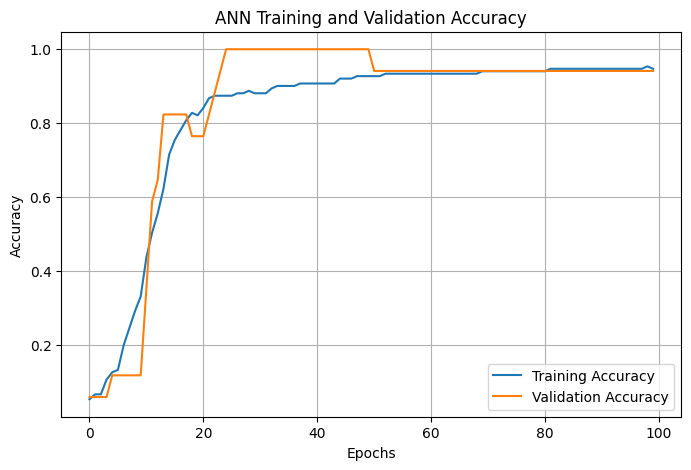

In [148]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

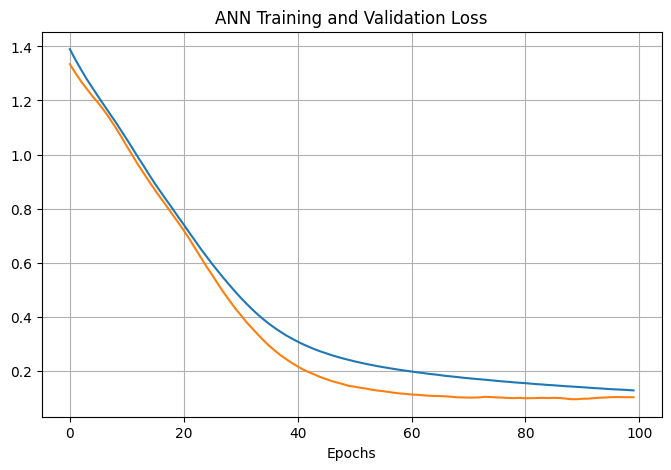

In [151]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.title("ANN Training and Validation Loss")
plt.xlabel("Epochs")
plt.grid(True)
plt.show()

In [152]:
test_loss,test_accuracy=model.evaluate(X_test_scaled,y_test,verbose=1)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9048 - loss: 0.2101
Test Loss: 0.21005776524543762
Test Accuracy: 0.9047619104385376


In [153]:
y_prob=model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
[[9.9535292e-01 5.5324624e-04 4.0938621e-03]
 [5.3561185e-03 4.0762339e-04 9.9423623e-01]
 [2.2020275e-03 9.9632794e-01 1.4700112e-03]
 [9.0889299e-01 2.2897501e-03 8.8817239e-02]
 [4.7342578e-01 8.1263779e-04 5.2576160e-01]]


In [156]:
y_pred=np.argmax(y_prob,axis=1)
print("Predicted Encoded Classes")
print(y_pred[:10])

Predicted Encoded Classes
[0 2 1 0 2 2 0 2 0 2]


In [157]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print("Predicted Classes:")
print(y_pred_original[:10])

Predicted Classes:
[1 3 2 1 3 3 1 3 1 3]


In [158]:
comparison_df=pd.DataFrame({"Actual Class":y_test_original,"Predicted Class":y_pred_original})
comparison_df.head(15)

,Actual Class,Predicted Class
30,1,1
172,3,3
84,2,2
199,3,1
60,1,3
155,3,3
45,1,1
182,3,3
9,1,1
196,3,3


In [159]:
accuracy=accuracy_score(y_test_original,y_pred_original)
precision=precision_score(y_test_original,y_pred_original,average='weighted')
recall=recall_score(y_test_original,y_pred_original,average='weighted')
f1=f1_score(y_test_original,y_pred_original,average='weighted')
print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

Accuracy: 0.9047619047619048
Precision: 0.9047619047619048
Recall: 0.9047619047619048
F1 Score: 0.9047619047619048
